In [12]:
import pandas as pd
from scipy.stats import mannwhitneyu, kstest, shapiro
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
import seaborn as sns

#### Задание 1
Вам подготовили датасет в файле compare_df.csv<br>
В нем есть всего две колонки sample1 и sample2<br>
Проведите Mann U Whitney тест чтобы проверить, идентично ли распределение двух этих сэмплов с уровнем значимости в 95%

Mann–Whitney U-test: U=4409.000, p-value=0.149


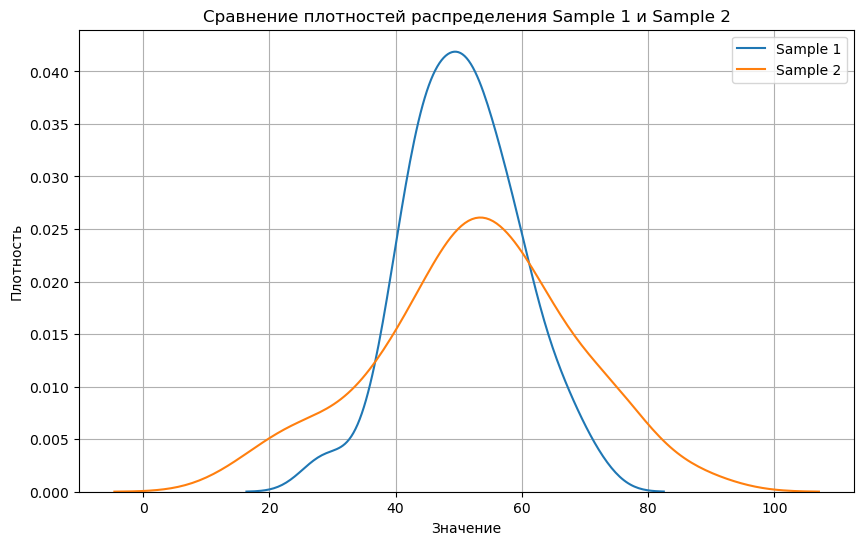

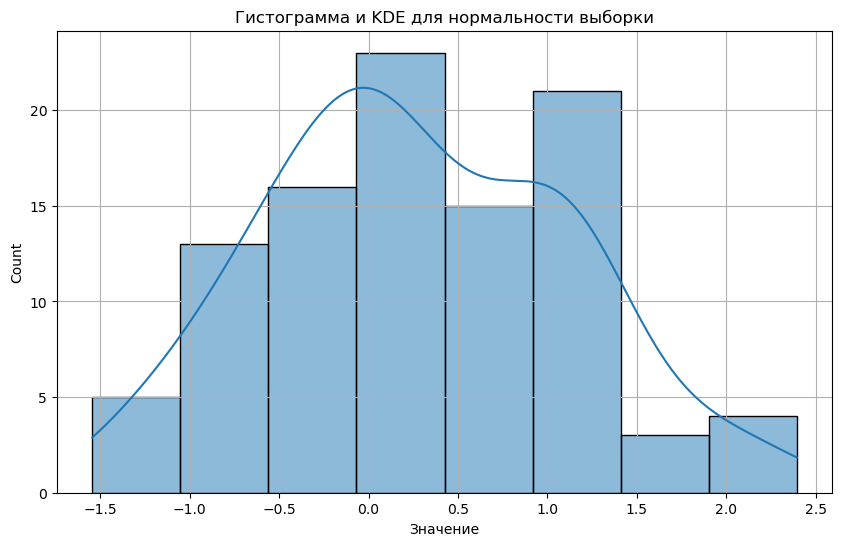

In [17]:
#  Mann–Whitney U и Kolmogorov–Smirnov тест для двух выборок
compare_df = pd.read_csv('compare_df.csv')
sample1 = compare_df['sample1'].dropna()
sample2 = compare_df['sample2'].dropna()

# Mann–Whitney U test
u_stat, u_p = mannwhitneyu(sample1, sample2)
print(f"Mann–Whitney U-test: U={u_stat:.3f}, p-value={u_p:.3f}")


# Визуализация распределений
plt.figure(figsize=(10, 6))
sns.kdeplot(sample1, label='Sample 1')
sns.kdeplot(sample2, label='Sample 2')
plt.title('Сравнение плотностей распределения Sample 1 и Sample 2')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(sample, kde=True)
plt.title('Гистограмма и KDE для нормальности выборки')
plt.xlabel('Значение')
plt.grid()
plt.show()



#### Задание 2
Используя те же самые два сэмпла из compare_df, проведите Kolmogorov Smirnov тест для проверки идентичности распределений

In [14]:
# Kolmogorov–Smirnov test (две выборки)
ks_stat, ks_p = ks_2samp(sample1, sample2)
print(f"Kolmogorov–Smirnov test (2 samples): D={ks_stat:.3f}, p-value={ks_p:.3f}")



Kolmogorov–Smirnov test (2 samples): D=0.200, p-value=0.036


#### Задание 3
Вам подготовили датасет в файле normality_test.csv<br>
В нем всего одна колонка sample<br>
Проведите Kolmogorov Smirnov тест, чтобы проверить нормальность данных с уровнем значимости в 95%

In [16]:
# тесты на нормальность
normality_df = pd.read_csv('normality_test.csv')
sample = normality_df['sample'].dropna()

# Kolmogorov–Smirnov test (нормальность)
ks_norm_stat, ks_norm_p = kstest(sample, 'norm', args=(sample.mean(), sample.std()))
print(f"Kolmogorov–Smirnov test (normality): D={ks_norm_stat:.3f}, p-value={ks_norm_p:.3f}")

Kolmogorov–Smirnov test (normality): D=0.075, p-value=0.601


#### Задание 4
Используя те же самые данные, проведите тест на нормальность используя Shapiro Wilk тест<br>
Какому тесту (ШапироУилк или КолмогоровСмирнов) вы доверяете больше и чей результат выберите?

In [11]:
# Shapiro–Wilk test
shapiro_stat, shapiro_p = shapiro(sample)
print(f"Shapiro–Wilk test: W={shapiro_stat:.3f}, p-value={shapiro_p:.3f}")


Shapiro–Wilk test: W=0.987, p-value=0.459
